## Objetivo del árbol de decisión

El objetivo de esta actividad es construir un modelo de clasificación mediante un árbol de decisión que permita identificar si un día presenta una cantidad baja o alta de accidentes de tránsito en Barranquilla, utilizando información relacionada con la clase de accidente, los comparendos y el tipo de vehículo del infractor.

Para este ejercicio, se definieron dos categorías:

- **Clase 0 – Accidentes bajos:** días con 8 accidentes o menos.
- **Clase 1 – Accidentes altos:** días con más de 8 accidentes.

El límite de 8 accidentes se estableció tomando como referencia la mediana obtenida durante el análisis exploratorio de los datos.

## ¿Qué se buscó predecir?

Se buscó clasificar la cantidad diaria de accidentes en dos categorías: baja o alta. El modelo no predice un número exacto de accidentes ni determina si habrá fallecidos; clasifica los registros según el umbral definido.

## Variables utilizadas

El árbol utiliza las siguientes variables para realizar la clasificación:

- **Clase del accidente:** identifica si el registro corresponde a un choque, atropello, caída de ocupante, volcamiento u otra clase.
- **Comparendos:** cantidad diaria de comparendos registrados.
- **Clase del vehículo del infractor:** permite identificar categorías como automóvil, camioneta o motocicleta.
- **Servicio del vehículo del infractor:** distingue las categorías disponibles, como servicio particular.

## ¿Qué preguntas realizó el árbol de decisión?

El árbol no formula preguntas en lenguaje natural; evalúa condiciones sobre las variables para decidir a qué categoría pertenece cada registro. En este modelo, las condiciones principales fueron:

1. **¿La clase de accidente corresponde a choque?**  
   Si la variable `CLASE_ACCIDENTE_Choque` es 0, el árbol clasifica el día como de accidentes bajos. Si es 1, continúa evaluando otras condiciones.

2. **¿La cantidad de comparendos es menor o igual a 95,5?**  
   Si se cumple, el árbol analiza cantidades menores o iguales a 8 y otros intervalos de comparendos para asignar una clase.

3. **¿El vehículo del infractor corresponde a un automóvil?**  
   Cuando los comparendos superan 95,5, el árbol evalúa esta variable para continuar la clasificación.

4. **¿La cantidad de comparendos supera 217,5?**  
   En una de las ramas del árbol, si corresponde a automóvil y los comparendos superan 217,5, el modelo clasifica el día como de accidentes altos.

Estas condiciones son las que aparecen en las reglas extraídas del árbol. Los valores decimales son puntos de separación que el algoritmo calculó automáticamente.

## Evaluación del modelo

Los datos se dividieron en dos conjuntos: 80 % para entrenamiento (2.437 registros) y 20 % para prueba (610 registros). El árbol se configuró con una profundidad máxima de cuatro niveles.

Los resultados fueron:

- **Accuracy de entrenamiento:** 57,49 %.
- **Accuracy de prueba:** 61,31 %.
- **Registros de prueba clasificados correctamente:** 374 de 610.

Los resultados indican que el modelo logra clasificar los días en las dos categorías, aunque todavía presenta dificultades para identificar algunos días con accidentalidad alta.

## 1. Separación de datos en entrenamiento y prueba

In [1]:
import os
import sys
import importlib

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Agregar la carpeta src a la ruta de búsqueda de Python
ruta_src = os.path.abspath("../src")

if ruta_src not in sys.path:
    sys.path.insert(0, ruta_src)

# Importar la clase de preparación de datos
import preparador_arbol
importlib.reload(preparador_arbol)

PreparacionArbol = preparador_arbol.PreparacionArbol

print("Librerías y clase importadas correctamente.")


Librerías y clase importadas correctamente.


## 2. Preparacion de los datos  
## 3. Uso random_state fijo
## 4. Codificacion de variables categóricas antes del fit

In [2]:

preparacion = PreparacionArbol(
    "../dataset/dataset_categorizado_arbol.csv"
)

preparacion.cargar_datos()

X, y = preparacion.preparar_variables()

X_train, X_test, y_train, y_test = (
    preparacion.separar_train_test(X, y)
)


Dataset cargado correctamente.
Dimensiones: (3047, 26)
Columnas: ['FECHA', 'ACCIDENTES', 'GRAVEDAD_ACCIDENTE', 'PRECIPITACION_MM', 'COMPARENDOS', 'PRECIPITACION_FALTANTE', 'CLASE_ACCIDENTE_Atropello', 'CLASE_ACCIDENTE_Caida Ocupante', 'CLASE_ACCIDENTE_Choque', 'CLASE_ACCIDENTE_Otro', 'CLASE_ACCIDENTE_Volcamiento', 'LLUVIA_No', 'LLUVIA_Sin dato', 'LLUVIA_Sí', 'COD_INFRACCION_C02', 'COD_INFRACCION_C14', 'COD_INFRACCION_C29', 'COD_INFRACCION_Sin dato', 'TIPO_INFRACCION_Sin dato', 'TIPO_INFRACCION_TRÁNSITO', 'CLASE_VEHICULO_INFRACTOR_AUTOMOVIL', 'CLASE_VEHICULO_INFRACTOR_CAMIONETA', 'CLASE_VEHICULO_INFRACTOR_MOTOCICLETA', 'CLASE_VEHICULO_INFRACTOR_Sin dato', 'SERVICIO_VEHICULO_INFRACTOR_PARTICULAR', 'SERVICIO_VEHICULO_INFRACTOR_Sin dato']

Variables predictoras:
['COMPARENDOS', 'CLASE_ACCIDENTE_Atropello', 'CLASE_ACCIDENTE_Caida Ocupante', 'CLASE_ACCIDENTE_Choque', 'CLASE_ACCIDENTE_Otro', 'CLASE_ACCIDENTE_Volcamiento', 'CLASE_VEHICULO_INFRACTOR_AUTOMOVIL', 'CLASE_VEHICULO_INFRACTOR_CAMIONE

## 5. Medicion del accuracy en entrenamiento y prueba

In [3]:
# Crear el árbol de decisión con máximo 4 niveles
modelo = DecisionTreeClassifier(
    max_depth=4,
    random_state=42
)

# Entrenar el árbol con los datos de entrenamiento
modelo.fit(X_train, y_train)

print("Árbol de decisión entrenado correctamente.")
print("Profundidad real:", modelo.get_depth())
print("Número de hojas:", modelo.get_n_leaves())


Árbol de decisión entrenado correctamente.
Profundidad real: 4
Número de hojas: 7


In [4]:
# Realizar predicciones con los datos de entrenamiento y prueba
predicciones_train = modelo.predict(X_train)
predicciones_test = modelo.predict(X_test)

# Calcular accuracy
accuracy_train = accuracy_score(y_train, predicciones_train)
accuracy_test = accuracy_score(y_test, predicciones_test)

# Mostrar resultados
print(f"Accuracy en entrenamiento: {accuracy_train:.2%}")
print(f"Accuracy en prueba: {accuracy_test:.2%}")

# Mostrar el reporte de clasificación en los datos de prueba
print("\nReporte de clasificación:")
print(classification_report(
    y_test,
    predicciones_test,
    labels=[0, 1],
    target_names=["Accidentes bajos", "Accidentes altos"],
    zero_division=0
))


Accuracy en entrenamiento: 57.49%
Accuracy en prueba: 61.31%

Reporte de clasificación:
                  precision    recall  f1-score   support

Accidentes bajos       0.64      0.66      0.65       331
Accidentes altos       0.58      0.56      0.57       279

        accuracy                           0.61       610
       macro avg       0.61      0.61      0.61       610
    weighted avg       0.61      0.61      0.61       610



## 6. Graficacion del árbol de decisión

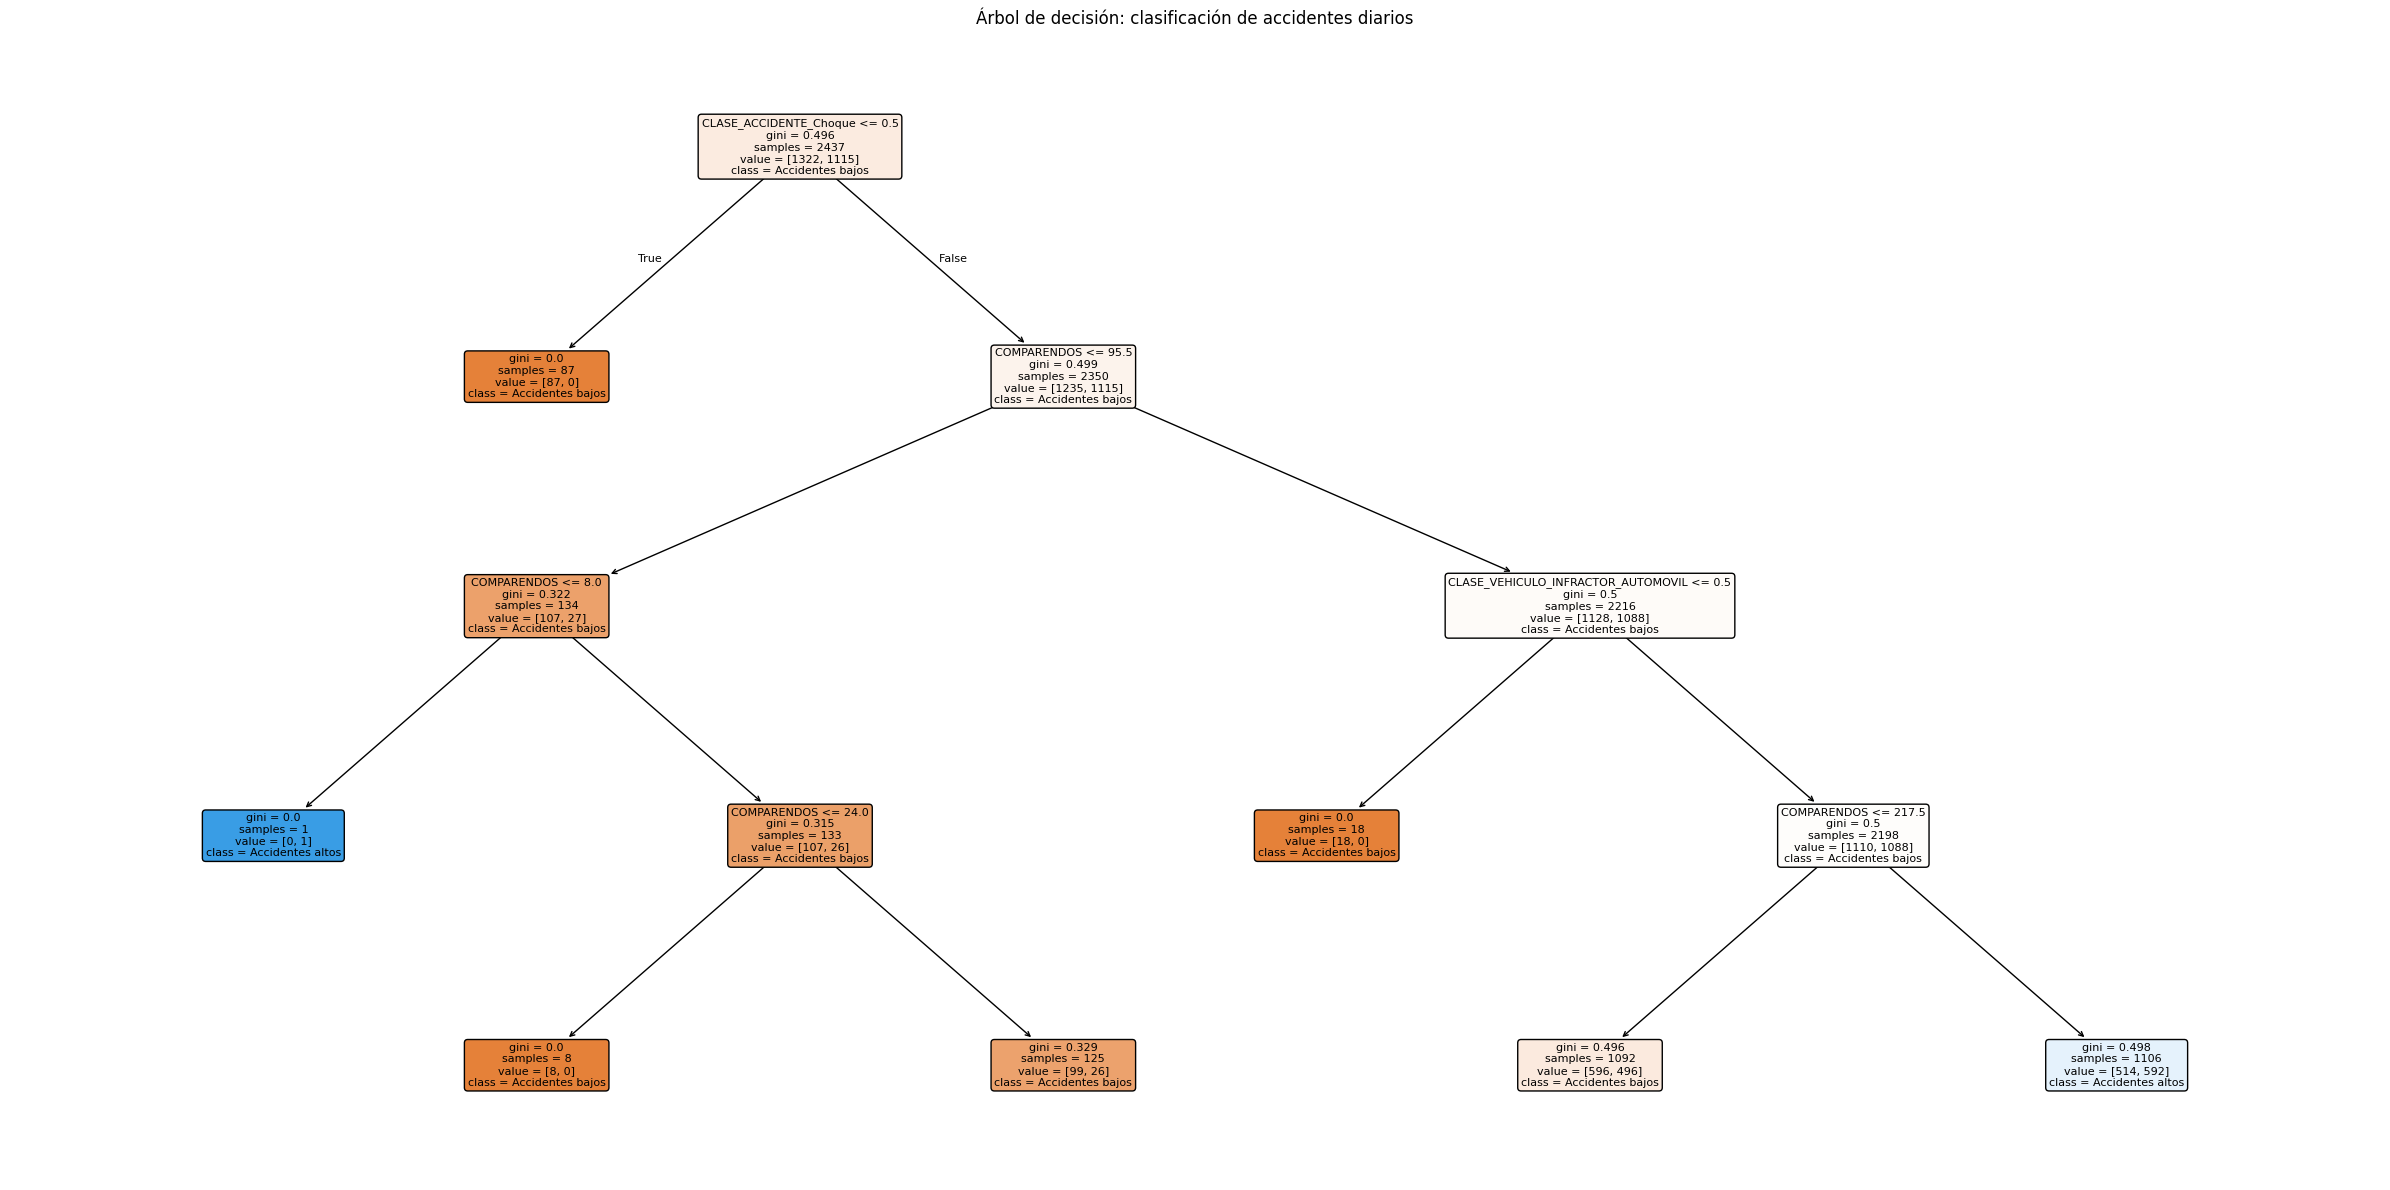

Diagrama guardado en: c:\Users\Loren\OneDrive\Documentos\Septimo y Octavo semestre\Mineria de datos 2026-2\mineria-datos-accidentes-v2\docs\diagramas\arbol_decision_accidentes.png


In [5]:
# Crear la carpeta si todavía no existe
ruta_diagramas = "../docs/diagramas"
os.makedirs(ruta_diagramas, exist_ok=True)

# Crear la gráfica del árbol
plt.figure(figsize=(24, 12))

plot_tree(
    modelo,
    feature_names=X_train.columns.tolist(),
    class_names=["Accidentes bajos", "Accidentes altos"],
    filled=True,
    rounded=True,
    max_depth=4,
    fontsize=8
)

plt.title("Árbol de decisión: clasificación de accidentes diarios")
plt.tight_layout()

# Guardar el diagrama como PNG
ruta_png = os.path.join(
    ruta_diagramas,
    "arbol_decision_accidentes.png"
)

plt.savefig(ruta_png, dpi=300, bbox_inches="tight")

# Mostrar la gráfica
plt.show()

print(f"Diagrama guardado en: {os.path.abspath(ruta_png)}")

## 7. Extraer las reglas con export_text

In [6]:
reglas = export_text(
    modelo,
    feature_names=X_train.columns.tolist(),
    max_depth=4
)

print("REGLAS DEL ÁRBOL DE DECISIÓN")
print(reglas)


REGLAS DEL ÁRBOL DE DECISIÓN
|--- CLASE_ACCIDENTE_Choque <= 0.50
|   |--- class: 0
|--- CLASE_ACCIDENTE_Choque >  0.50
|   |--- COMPARENDOS <= 95.50
|   |   |--- COMPARENDOS <= 8.00
|   |   |   |--- class: 1
|   |   |--- COMPARENDOS >  8.00
|   |   |   |--- COMPARENDOS <= 24.00
|   |   |   |   |--- class: 0
|   |   |   |--- COMPARENDOS >  24.00
|   |   |   |   |--- class: 0
|   |--- COMPARENDOS >  95.50
|   |   |--- CLASE_VEHICULO_INFRACTOR_AUTOMOVIL <= 0.50
|   |   |   |--- class: 0
|   |   |--- CLASE_VEHICULO_INFRACTOR_AUTOMOVIL >  0.50
|   |   |   |--- COMPARENDOS <= 217.50
|   |   |   |   |--- class: 0
|   |   |   |--- COMPARENDOS >  217.50
|   |   |   |   |--- class: 1



## 8. Reglas interpretables en lenguaje de negocio

Regla 1. Días sin accidentes de choque

Cuando la variable CLASE_ACCIDENTE_Choque es 0, el árbol clasifica el día en la categoría de accidentes bajos (clase 0), es decir, días con 8 accidentes o menos.

Regla 2. Días con choques y muchos comparendos

Cuando hay accidentes de choque, se registran más de 95 comparendos y la variable CLASE_VEHICULO_INFRACTOR_AUTOMOVIL es 1, si los comparendos superan los 217,5, el árbol clasifica el día en accidentes altos (clase 1), es decir, más de 8 accidentes.

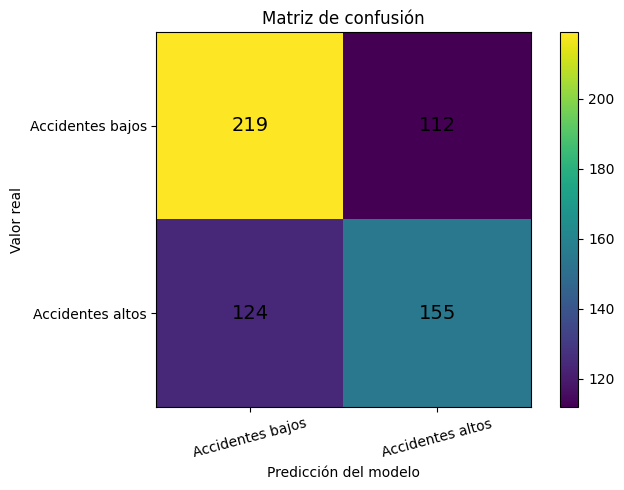

Matriz de confusión:
[[219 112]
 [124 155]]


In [7]:
# Calcular la matriz de confusión
matriz = confusion_matrix(y_test, predicciones_test, labels=[0, 1])

# Mostrar los resultados como gráfica
plt.figure(figsize=(7, 5))

plt.imshow(matriz, interpolation="nearest")
plt.title("Matriz de confusión")
plt.colorbar()

plt.xticks(
    [0, 1],
    ["Accidentes bajos", "Accidentes altos"],
    rotation=15
)
plt.yticks(
    [0, 1],
    ["Accidentes bajos", "Accidentes altos"]
)

plt.xlabel("Predicción del modelo")
plt.ylabel("Valor real")

# Mostrar los valores dentro de cada casilla
for fila in range(2):
    for columna in range(2):
        plt.text(
            columna,
            fila,
            matriz[fila, columna],
            ha="center",
            va="center",
            fontsize=14
        )

plt.tight_layout()
plt.show()

print("Matriz de confusión:")
print(matriz)

### Interpretación de la matriz de confusión

| Resultado | Cantidad | Interpretación |
|---|---:|---|
| Verdaderos negativos (VN) | 219 | Días con 8 accidentes o menos clasificados correctamente. |
| Falsos positivos (FP) | 112 | Días con 8 accidentes o menos clasificados como accidentes altos. |
| Falsos negativos (FN) | 124 | Días con más de 8 accidentes clasificados como accidentes bajos. |
| Verdaderos positivos (VP) | 155 | Días con más de 8 accidentes clasificados correctamente. |

**Conclusión:** El modelo clasificó correctamente 374 de los 610 registros de prueba, con un accuracy del 61,31 %. Sin embargo, clasificó incorrectamente 124 registros con accidentes altos como accidentes bajos, lo que evidencia dificultades para identificar los días de mayor accidentalidad.